# Airbnb Market Analysis: Barcelona vs Berlin vs Amsterdam
## 02 – Analysis

This notebook focuses on three visual analyses that go beyond aggregated figures: where supply is concentrated, how prices are distributed, and how occupancy is distributed across the year.

Aggregated figures for all business questions are computed in SQL (see the `sql/` folder), and the main indicators are presented in the interactive dashboard.

In [26]:
#Setup

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load clean data
listings = pd.read_csv(
    'C:/Users/Usuario/Desktop/Data Analysis/Portfolio/Inside_Airbnb/data/clean/listings_clean.csv',
    parse_dates=['last_review'],
    low_memory=False
)

# Consistent settings for all charts
CITY_ORDER = ['Amsterdam', 'Barcelona', 'Berlin']
CITY_COLORS = {'Amsterdam': '#E07A5F', 'Barcelona': '#3D85C6', 'Berlin': '#81B29A'}

sns.set_theme(style='whitegrid')

listings.shape

(38224, 24)

## 1. Q1 – Supply size: geographic concentration

Listings are counted per hexagon within the same 20 x 20 km window around each city centre, so that concentration is comparable between cities (one kilometre covers the same area in all three maps). A logarithmic colour scale is used because central hexagons contain hundreds of listings while outer ones contain only a few.

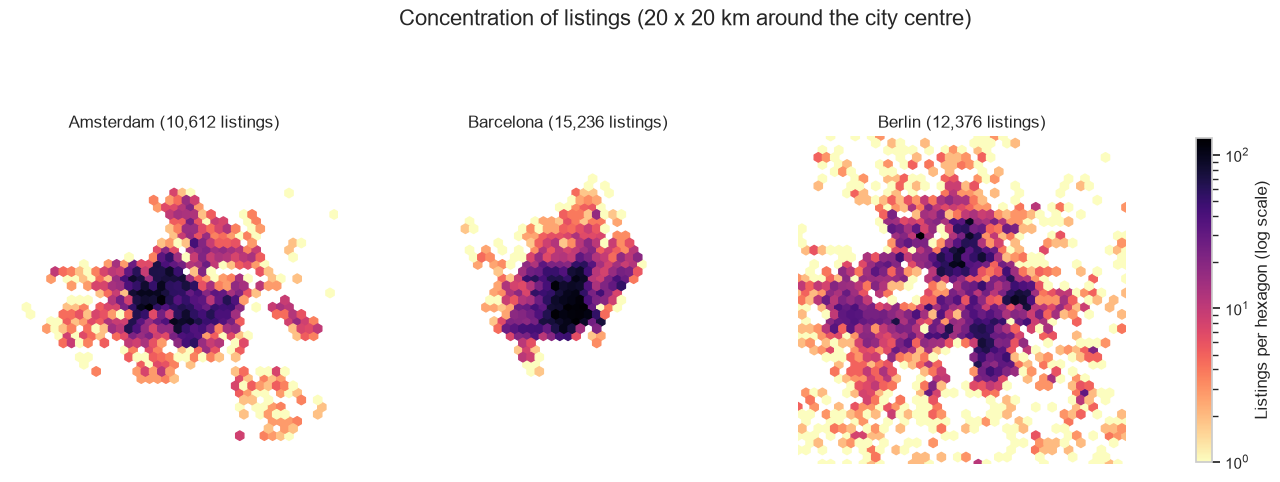

In [28]:
import numpy as np

HALF_KM = 10  # 20 x 20 km window around each city centre

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, city in zip(axes, CITY_ORDER):
    city_data = listings[listings['city'] == city]
    lat0 = city_data['latitude'].median()
    lon0 = city_data['longitude'].median()

    # Convert km to degrees (1 degree of latitude ~ 111 km)
    dlat = HALF_KM / 111
    dlon = HALF_KM / (111 * np.cos(np.radians(lat0)))

    hb = ax.hexbin(
        city_data['longitude'], city_data['latitude'],
        gridsize=40, bins='log', cmap='magma_r', mincnt=1,
        extent=(lon0 - dlon, lon0 + dlon, lat0 - dlat, lat0 + dlat)
    )
    ax.set_xlim(lon0 - dlon, lon0 + dlon)
    ax.set_ylim(lat0 - dlat, lat0 + dlat)
    ax.set_aspect(1 / np.cos(np.radians(lat0)))
    ax.set_title(f'{city} ({len(city_data):,} listings)')
    ax.set_axis_off()

fig.colorbar(hb, ax=axes, shrink=0.7, label='Listings per hexagon (log scale)')
fig.suptitle('Concentration of listings (20 x 20 km around the city centre)', fontsize=16)
plt.savefig('../visuals/01_maps.png', dpi=150, bbox_inches='tight')
plt.show()

- **Barcelona** has a **single, very dense core** (Eixample and the old town): the whole city fits in the window and supply is highly concentrated.
- **Amsterdam** shows a **dense ring around the historic centre** that fades towards the outskirts (gaps are partly water and green areas).
- **Berlin** is **polycentric**: it extends beyond the window and has several separate dense clusters rather than one centre.

Berlin's central areas reach a concentration similar to Barcelona and Amsterdam. This suggests that its low density per 1,000 residents (3.2 listings, vs 11.3 in Amsterdam and 8.8 in Barcelona; see `q1_supply_size.sql`) is largely explained by its size and residential outskirts, not by a lack of supply in central areas.

## 2. Q2 – Pricing: price distribution

Boxes show the middle 50% of listings (25th to 75th percentile), with the line inside marking the median. *Listings with a price, excluding outliers; entire homes and private rooms only.*

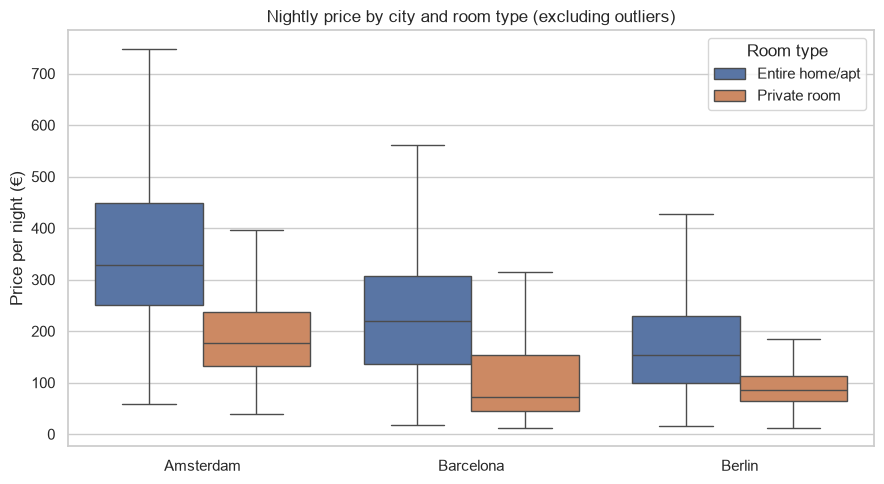

In [29]:
price_data = listings[
    (listings['price'].notna()) &
    (~listings['is_price_outlier']) &
    (listings['room_type'].isin(['Entire home/apt', 'Private room']))
]

fig, ax = plt.subplots(figsize=(9, 5))

sns.boxplot(
    data=price_data, x='city', y='price', hue='room_type',
    order=CITY_ORDER, showfliers=False, ax=ax
)

ax.set_title('Nightly price by city and room type (excluding outliers)')
ax.set_xlabel('')
ax.set_ylabel('Price per night (€)')
ax.legend(title='Room type')

plt.tight_layout()
plt.savefig('../visuals/02_price_boxplot.png', dpi=150, bbox_inches='tight')
plt.show()

**Amsterdam is the most expensive market for both room types.** A median entire home costs **329€** per night in Amsterdam, **220€** in Barcelona and **154€** in Berlin. Since the gap holds within the same room type, it is not explained by differences in supply mix.

**Private rooms in Amsterdam (176€) cost more than twice as much** as in Berlin (85€) or Barcelona (73€), at a price close to a hotel room.

In Barcelona, private room prices are particularly dispersed, with a mean far above the median, suggesting a mix of very cheap rooms and a smaller group of expensive ones.

*Comparing like for like (see `q2_pricing.sql`, query 2.3), Barcelona and Berlin differ mainly in small units, while 2- and 3-bedroom homes are priced almost equally.*

## 3. Q3 – Performance: occupancy distribution

Medians summarise occupancy in a single number, but the full distribution shows how listings actually operate. The dashed line marks Amsterdam's 30-night cap on holiday rentals of entire homes. *Active entire homes (occupancy > 0).*

*Note: occupancy is estimated by Inside Airbnb from reviews and capped at 70% of the year (~255 nights). The bar at ~255 nights therefore groups all listings that reach this cap; their actual occupancy may be higher.*

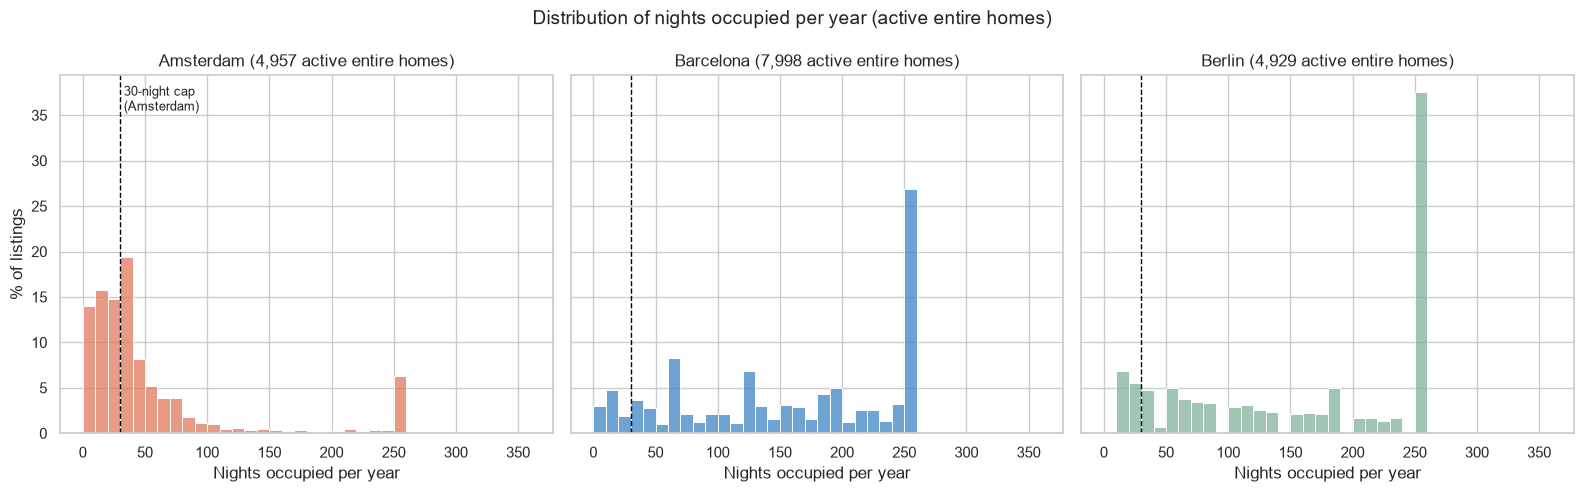

In [30]:
occ_data = listings[
    (listings['room_type'] == 'Entire home/apt') &
    (listings['estimated_occupancy_l365d'] > 0)
]

fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharex=True, sharey=True)

for ax, city in zip(axes, CITY_ORDER):
    city_data = occ_data[occ_data['city'] == city]

    sns.histplot(
        data=city_data, x='estimated_occupancy_l365d',
        bins=range(0, 370, 10), stat='percent',
        color=CITY_COLORS[city], ax=ax
    )

    ax.axvline(30, color='black', linestyle='--', linewidth=1)
    ax.set_title(f'{city} ({len(city_data):,} active entire homes)')
    ax.set_xlabel('Nights occupied per year')

axes[0].set_ylabel('% of listings')
axes[0].text(33, axes[0].get_ylim()[1] * 0.9, '30-night cap\n(Amsterdam)', fontsize=9)

fig.suptitle('Distribution of nights occupied per year (active entire homes)', fontsize=14)
plt.tight_layout()
plt.savefig('../visuals/03_occupancy_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

**Amsterdam's entire homes cluster around the 30-night cap:** most listings are occupied between 0 and 60 nights per year, with the highest peak just around the cap (30–40 nights). This shows the effect of regulation much more directly than the median (31 nights). A small group (around 6%) reaches the model's cap of ~255 nights, consistent with the multi-listing and professional hosts that operate far above the 30-night limit (see `q4_professionalisation.sql`, query 4.2).

**In Barcelona and Berlin, occupancy is spread across the whole year**, and a large share of entire homes reaches the cap of ~255 nights: these listings are occupied almost year-round, operating as full-time accommodation that competes directly with hotels.

As a result, despite having the highest nightly prices, Amsterdam's entire homes generate the lowest median revenue of the three cities (11,821€ per year, vs 34,710€ in Barcelona and 27,540€ in Berlin; see `q3_performance.sql`).

## Summary

- **Supply** concentrates in a single dense core in Barcelona, a central ring in Amsterdam and several clusters in Berlin.
- **Amsterdam** is the most expensive market, but its entire homes are limited to around 30 nights per year by regulation, which keeps their revenue the lowest of the three cities.
- **Barcelona and Berlin** operate as year-round markets, where entire homes compete directly with hotels.